In [5]:
import networkx as nx
import numpy as np

# Questão 1
A média medida eigenvector centrality da rede USairport500 é igual a quanto? Considere apenas o maior componente.

In [32]:
G_USairport500 = nx.read_edgelist('data/data/USairport500.txt')

def get_largest_component(G):
    G = G.to_undirected()
    G.remove_edges_from(nx.selfloop_edges(G))
    Gcc = sorted(nx.connected_components(G), key=len, reverse=True)
    G = G.subgraph(Gcc[0])
    G = nx.convert_node_labels_to_integers(G, first_label=0)
    return G

np.mean(list(nx.eigenvector_centrality(get_largest_component(G_USairport500)).values()))

np.float64(0.022754398239423664)

# Questão 2
Calcule a correlação de Pearson entre a medida betweeness centrality e grau para a rede hamsterster.

In [18]:
G_hamsterster = nx.read_edgelist('data/data/hamsterster.txt')

values_betweeness = list(nx.betweenness_centrality(get_largest_component(G_hamsterster)).values())
values_degree = list(nx.degree_centrality(get_largest_component(G_hamsterster)).values())

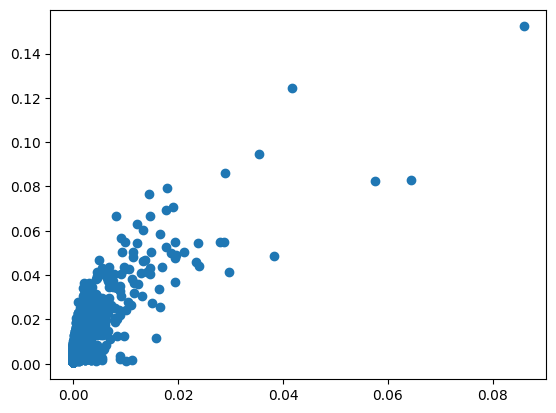

array([[1.        , 0.82424352],
       [0.82424352, 1.        ]])

In [19]:
import matplotlib.pyplot as plt

plt.scatter(values_betweeness, values_degree)
plt.show()

np.corrcoef(values_betweeness, values_degree)

# Questão 3
Calcule o coeficiente de correlação de Spearman entre as medidas closeness centrality e k-core para a rede "Jazz".

In [36]:
G_jazz = nx.read_edgelist('data/data/jazz.txt')

G_jazz = get_largest_component(G_jazz)
values_closeness = list(nx.closeness_centrality(G_jazz).values())
values_kcore = list(nx.core_number(G_jazz).values())

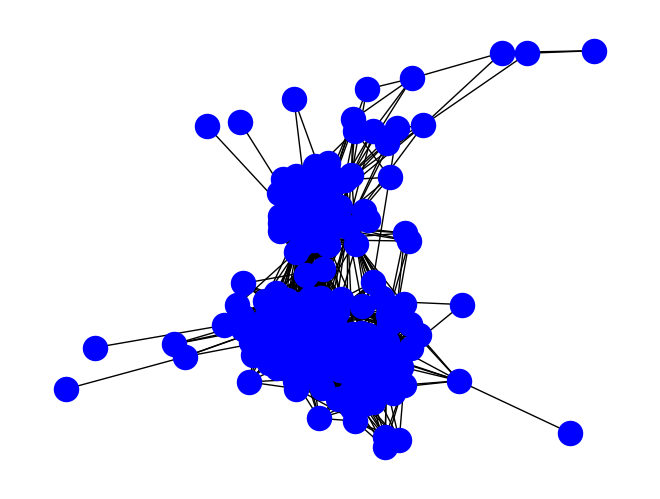

In [29]:
nx.draw(G_jazz, node_color='b', pos=nx.spring_layout(G_jazz, k=0.15, iterations=100))

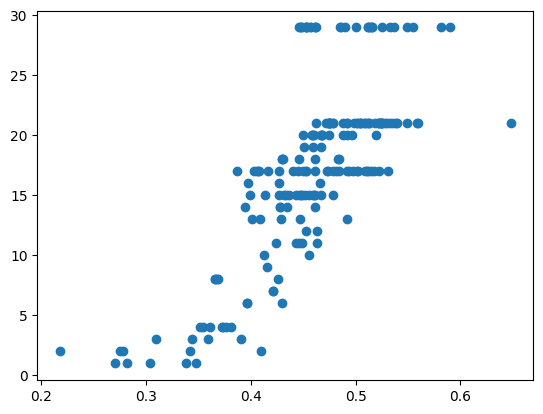

SignificanceResult(statistic=np.float64(0.7353399833516918), pvalue=np.float64(5.88940327932059e-35))

In [37]:
plt.scatter(values_closeness, values_kcore)
plt.show()

from scipy import stats
stats.spearmanr(values_closeness, values_kcore)